# 03.4 · 分层回测（Layered / Quantile Backtest）

> IC 告诉我们因子"统计上"有没有预测力，而**分层回测**更进一步：**真的按因子把股票分组、持有、调仓，看钱能不能赚到手**。它是最直观、最贴近交易的单因子检验。
>
> 本节会对比：**弱因子（反转）分层不单调、多空不赚钱；强因子（小市值）分层单调、多空稳定赚钱**。

## 一、什么是分层回测

做法：
1. 每个交易日，按因子值把股票**由低到高分成 N 组**（如 5 组，每组股票数相近）；
2. 每组内**等权**（或市值加权）持有；
3. 定期（这里每日）按最新因子重新分组、调仓；
4. 观察：
   - **各组收益是否单调**（Q1 最差 → Q5 最好）；
   - **多空组合（Q5 − Q1）能否稳定赚钱**；
   - 净值、年化、夏普、最大回撤、换手率。

**为什么用分位数分组？** 保证每组股票数量相近，结果可比；等权则避免少数大市值股票主导。

> 关键防前视：**t 日收盘的因子分组，只能赚 t+1 日的收益**。

## 二、准备数据

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.layered import (layered_returns, perf_metrics, turnover)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close', '$mkt_cap_ard'], freq='day')
close = F['$close'].unstack('instrument')
mkt = F['$mkt_cap_ard'].unstack('instrument')
daily_ret = close.pct_change()
print('股票数:', len(codes), ' 交易日:', len(close))

[24580:MainThread](2026-10-29 19:49:21,722) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[24580:MainThread](2026-10-29 19:49:23,185) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[24580:MainThread](2026-10-29 19:49:23,186) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


股票数: 300  交易日: 2139


## 三、弱因子示范：5 日反转

先看 5 日反转因子（上节 IC 仅 0.023）。分层结果：各组收益**不单调、多空在 0 附近**——与 IC 的"弱"结论一致。

          1      2      3      4      5
年化收益  0.213  0.136  0.135  0.135  0.141
夏普    0.878  0.706  0.708  0.653  0.564
最大回撤 -0.298 -0.282 -0.240 -0.275 -0.327

多空: 年化 -0.072 夏普 -0.32


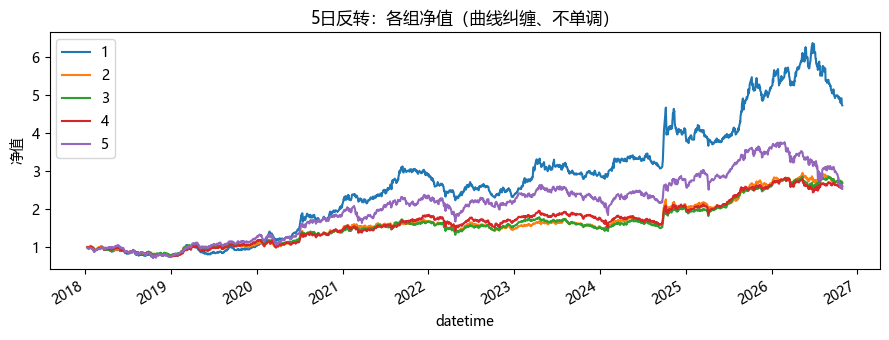

In [2]:
rev5 = -close.pct_change(5)
gr_rev, hold_rev = layered_returns(rev5, daily_ret)
m_rev = pd.DataFrame({g: perf_metrics(gr_rev[g]) for g in gr_rev.columns})
print(m_rev.round(3))
ls_rev = gr_rev[5] - gr_rev[1]
print('\n多空: 年化 %.3f 夏普 %.2f' % (ls_rev.mean()*252,
      ls_rev.mean()/ls_rev.std()*np.sqrt(252)))

(1+gr_rev).cumprod().plot(figsize=(9, 3.5))
plt.title('5日反转：各组净值（曲线纠缠、不单调）'); plt.ylabel('净值')
plt.tight_layout(); plt.show()

## 四、强因子示范：小市值（SMB）

**小市值因子 = −log(总市值)**：市值越小，因子值越大。这是 A 股最著名、最稳健的因子之一。
分层结果：**年化、夏普从 Q1 到 Q5 严格单调，多空稳定赚钱**。

In [3]:
smb = -np.log(mkt)
gr, hold = layered_returns(smb, daily_ret)
m = pd.DataFrame({g: perf_metrics(gr[g]) for g in gr.columns})
print(m.round(3))
ls = gr[5] - gr[1]
print('\n多空组合指标:'); print(perf_metrics(ls).round(3))

          1      2      3      4      5
年化收益  0.053  0.065  0.118  0.181  0.372
夏普    0.290  0.327  0.579  0.836  1.510
最大回撤 -0.364 -0.325 -0.281 -0.326 -0.282

多空组合指标:
年化收益    0.320
夏普      1.778
最大回撤   -0.225
dtype: float64


画各组净值和多空净值：

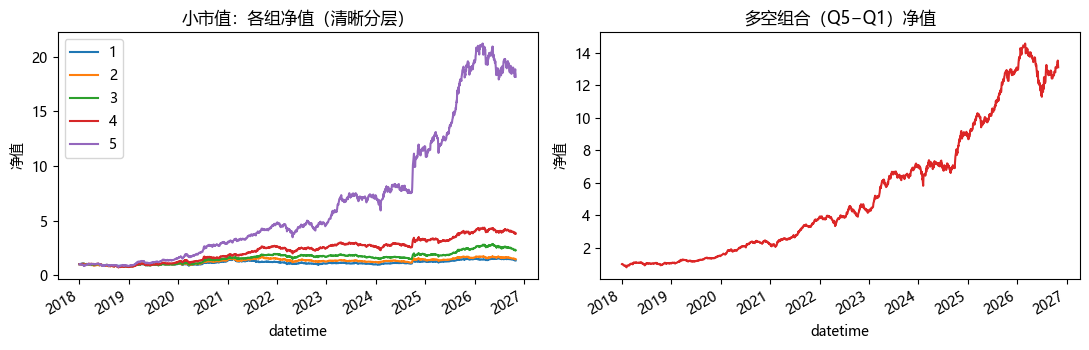

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
nav = (1+gr).cumprod()
nav.plot(ax=axes[0]); axes[0].set_title('小市值：各组净值（清晰分层）'); axes[0].set_ylabel('净值')
(1+ls).cumprod().plot(ax=axes[1], color='#dc2626')
axes[1].set_title('多空组合（Q5−Q1）净值'); axes[1].set_ylabel('净值')
plt.tight_layout(); plt.show()

**收益来源（小市值因子为什么有效？）**
- **风险补偿**：小公司经营更不稳定、信息更不透明、流动性更差，市场给持有者更高的预期回报；
- 行为偏差：小盘股被机构覆盖少，定价效率低，错误定价更多。

## 五、换手率：真实交易的成本

分层回测必须看**换手率**——换手越高，交易成本（佣金、印花税、冲击成本）侵蚀越大。

In [5]:
to = turnover(hold)
print('各组日均单边换手率:'); print(to.round(3))
print('（每日调仓，年化单边换手约 %.1f ~ %.1f 倍）' % (to.min()*252, to.max()*252))

# 粗略计入成本：双边千1.5（佣金+印花税近似），看对多空的影响
cost = 0.0015
to_ls = (turnover(hold)[5] + turnover(hold)[1])  # 多空两端
ls_net = ls - to_ls/252 * 0  # 日均换手已在上面，这里直接演示按日扣
# 更直接：每日按多空两端换手扣成本
def daily_turn(hold, g):
    m = (hold == g).astype(float); cnt = m.sum(axis=1).replace(0, np.nan)
    return ((m.diff() > 0).sum(axis=1)/cnt).fillna(0)
dtc = daily_turn(hold, 5) + daily_turn(hold, 1)
ls_net = ls - dtc * cost
print('\n扣成本后多空: 年化 %.3f 夏普 %.2f' % (
    ls_net.mean()*252, ls_net.mean()/ls_net.std()*np.sqrt(252)))

各组日均单边换手率:
1    0.013
2    0.032
3    0.041
4    0.042
5    0.020
dtype: float64
（每日调仓，年化单边换手约 3.2 ~ 10.5 倍）

扣成本后多空: 年化 0.307 夏普 1.71


## 六、小市值因子的风险（务必知道）

小市值因子虽然历史表现好，但有明确的风险，**面试时要主动讲，体现风险意识**：
- **容量有限**：小盘股流动性差，资金量大了买不进、卖不出，冲击成本高；
- **拥挤与踩踏**：2024 年 1–2 月「微盘股危机」，量化微盘策略集中平仓，小盘股指数短期暴跌；
- **风格会阶段性失效**：如 2017 年「漂亮 50」大盘蓝筹行情，小市值大幅跑输；
- 多空最大回撤约 −22%，并非稳赚。

> 这也是为什么模块 5 要做风险控制、模块 6 要做归因——单一因子再强也不能裸奔。

## 七、小结与面试要点

- **分层回测**：按因子分 N 组、等权、调仓，看**单调性 + 多空收益**，比 IC 更贴近交易。
- 弱因子（反转）分层不单调、多空≈0；强因子（小市值）严格单调、多空年化 32%、夏普 1.78。
- 必须看**换手率**并计入交易成本；小市值因子要警惕容量、拥挤、风格失效。
- 防前视：t 日信号只赚 t+1 日收益。

**面试高频：**
- 分层回测怎么做？为什么要分位数分组？（答：保证组间数量可比，等权避免大市值主导）
- 怎么判断一个因子分层有效？（答：各组收益/夏普单调、多空稳定为正且扣成本后仍有效）
- 小市值因子的收益来源和风险？（答：风险补偿+流动性溢价；风险是容量小、拥挤踩踏、风格失效）
- 换手率为什么重要？（答：高换手会被交易成本吃掉，回测好看但实盘不赚钱）

## 动手练习
1. 把分组数改成 10 组，看单调性是否依然成立；
2. 用市值加权（而非等权）重做分层，对比结果；
3. 计算 2024 年 1–2 月小市值多空的回撤，直观感受微盘股危机。

---
下一节 **03.5 因子库批量实现：把量价、基本面、风格因子系统化**。